## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [52]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [Roney Nguyen]

**Date:** [10/19/2026]

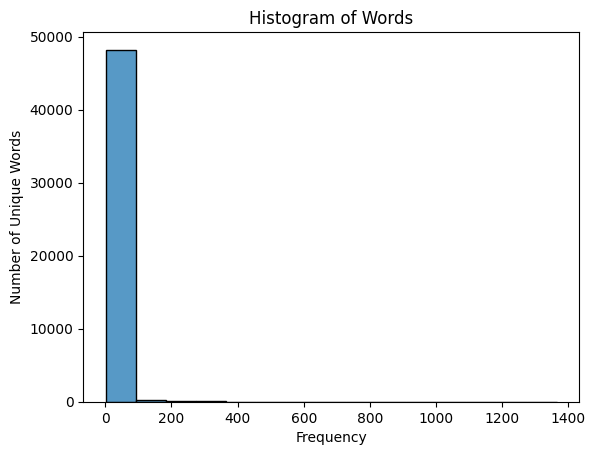

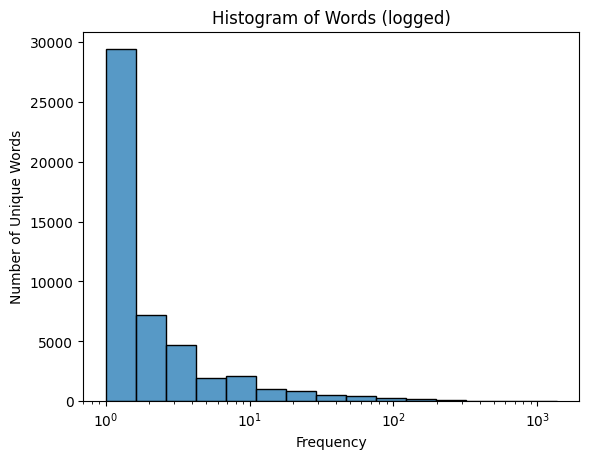

In [1]:
# Your Phase 1 solution to the problem goes here.
#Q1, run code
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

#Plot Histogram of all words
counts = [count for token, count in token_freq]

sns.histplot(counts, bins=15).set(title="Histogram of Words")
plt.xlabel("Frequency")
plt.ylabel("Number of Unique Words")
plt.show()

sns.histplot(counts, bins=15, log_scale=True).set(title="Histogram of Words (logged)")
plt.xlabel("Frequency")
plt.ylabel("Number of Unique Words")
plt.show()
#The frequency of tokens is very right skewed, 0-100/first bar makes up almost the entirety of the graph reaching up to ~50000, even after being scaled for log it is still apparent. This means that most unique words are only said a couple of times.


In [2]:
#Q2
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import pyarrow.parquet as pq

#Load data
table = pq.read_table("data/Phishing_clean.parquet")
df = table.to_pandas()

#1. Perform Train-test split
X = df.drop(columns=["Email Type"])
Y = df["Email Type"]
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=65
)

#2. Run regression of y
model = LinearRegression()
model.fit(X_train, Y_train)
#Run R^2 on test set
test_r2 = model.score(X_test, Y_test)
print("Test R2:", test_r2, "\n")
#On training set
train_r2 = model.score(X_train, Y_train)
print("Train R2:", train_r2, "\n")
#Test R2 is 0.657 and Train R2 is 0.767

#3. What words have the largest coefficients in absolute value and most strongly influence predictions
coefs = pd.Series(model.coef_, index=X.columns)
print("Top 10 Largest Coefficients:")
print(coefs.loc[coefs.abs().sort_values(ascending=False).head(10).index])
#The words that have the largest coefficient is aging, helvetica, localized, and background-image. Most seem to be css and html words rather than actual email content, but the most popular aging isn't.

Test R2: 0.6571173475409766 

Train R2: 0.7677733084118992 

Top 10 Largest Coefficients:
aging                0.996514
helvetica,           0.892177
localized            0.787934
background-image:   -0.780070
thermal              0.671019
12px;                0.629280
rcs                  0.553536
exercise!            0.542180
burning             -0.515023
#000000;             0.502902
dtype: float64


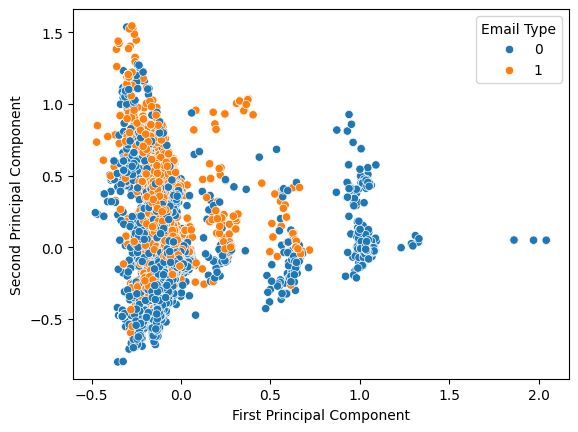

In [7]:
#Q3
from sklearn.decomposition import PCA

#Perform a PCA decomp
pca = PCA(n_components=2).fit(X)
X_pca = pca.transform(X)

#Plot the first two principal component in a scatter plot and hue the points by scam
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=Y)
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.show()
#Some patterns I see are that majority of the emails are below 0.0 FPC
#The higher the SPC, the more common fake emails are. 
#Fake emails tend to cluster around eachother.
#Almost all outliers in FPC are real emails.


In [ ]:
#Q4
#pca of 2610
pca = PCA(n_components=2610, svd_solver="full")
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

#run lin reg
linear_pca = LinearRegression()
linear_pca.fit(X_train_pca, Y_train)

#R2 of train and test
test_r2 = linear_pca.score(X_test_pca, Y_test)
print("Test PCA: ", test_r2, '\n')
train_r2 = linear_pca.score(X_train_pca, Y_train)
print("Train PCA: ", train_r2, '\n')
#Test R2 is 0.661 and Train R2 is 0.766

#Check linear regression values
print("Linear Regression Test: ", model.score(X_test, Y_test))
print("Linear Regression Train:", model.score(X_train, Y_train))
#Linear Test R2 is 0.657 and Train R2 is 0.767

#The performance of this compared to inear regression is nearly identical. Both are different from the linear regression values by the thousandths decimals, negligible.

Test PCA:  0.6613559301353324 

Train PCA:  0.7668967611277833 

Linear Regression Test:  0.6571173475409766
Linear Regression Train: 0.7677733084118992


In [12]:
#Q5
#Using principal components helps reduce the number of variables in the regression while keeping most of the important information. 
#It also removes issues with variables being highly correlated with each other, making the model simpler and reducing the risk of overfitting.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [13]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]